# Housing price prediction project 

In [2]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt

In [3]:
train=pd.read_csv(r"C:\Users\safal\OneDrive\Desktop\LEARNINGS\Coding\PYTHON AND LIBRARIES\Datasets\housing-price-prediction-2026\train.csv")

In [68]:
test=pd.read_csv(r"C:\Users\safal\OneDrive\Desktop\LEARNINGS\Coding\PYTHON AND LIBRARIES\Datasets\housing-price-prediction-2026\test.csv")

## Exploratory Data Analysis 

In [5]:
train.head()

,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,374,11.10810,0.0,18.10,0,0.668,4.906,100.0,1.1742,24,666,20.2,396.90,34.77,13.8
1,210,0.43571,0.0,10.59,1,0.489,5.344,100.0,3.8750,4,277,18.6,396.90,23.09,20.0
2,117,0.13158,0.0,10.01,0,0.547,6.176,72.5,2.7301,6,432,17.8,393.30,12.04,21.2
3,444,9.96654,0.0,18.10,0,0.740,6.485,100.0,1.9784,24,666,20.2,386.73,18.85,15.4
4,3,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7


In [6]:
train.shape

(355, 15)

In [7]:
train.info() # It gives broader info about the dataframe, what data type and how much numbers does it have 

<class 'pandas.DataFrame'>
RangeIndex: 355 entries, 0 to 354
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  355 non-null    int64  
 1   CRIM        355 non-null    float64
 2   ZN          355 non-null    float64
 3   INDUS       355 non-null    float64
 4   CHAS        355 non-null    int64  
 5   NOX         355 non-null    float64
 6   RM          355 non-null    float64
 7   AGE         355 non-null    float64
 8   DIS         355 non-null    float64
 9   RAD         355 non-null    int64  
 10  TAX         355 non-null    int64  
 11  PTRATIO     355 non-null    float64
 12  B           355 non-null    float64
 13  LSTAT       355 non-null    float64
 14  MEDV        355 non-null    float64
dtypes: float64(11), int64(4)
memory usage: 41.7 KB


In [8]:
train.describe() # describes mathematical properties about the graph 

,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
count,355.000000,355.000000,355.000000,355.000000,355.000000,355.000000,355.000000,355.000000,355.000000,355.000000,355.000000,355.000000,355.000000,355.000000,355.000000
mean,253.698592,3.338529,11.742254,10.949972,0.064789,0.555017,6.286113,68.887606,3.850169,9.580282,404.822535,18.432394,353.156197,12.547634,22.461408
std,148.119691,7.493918,23.029989,6.728985,0.246500,0.116227,0.712261,27.531821,2.085750,8.657720,167.684546,2.192525,96.409353,6.907105,9.059798
min,1.000000,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.980000,5.000000
25%,127.500000,0.082865,0.000000,5.160000,0.000000,0.451000,5.888000,45.250000,2.114600,4.000000,281.000000,17.000000,374.960000,7.130000,16.750000
50%,258.000000,0.268380,0.000000,8.560000,0.000000,0.538000,6.209000,77.700000,3.331700,5.000000,329.000000,19.000000,390.940000,11.650000,20.800000
75%,376.500000,3.675945,20.000000,18.100000,0.000000,0.624000,6.617000,93.950000,5.344000,24.000000,666.000000,20.200000,396.290000,16.550000,24.800000
max,506.000000,73.534100,95.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,36.980000,50.000000


In [9]:
train.isnull().sum() # Checking any NaN values is there and counting it 

Unnamed: 0    0
CRIM          0
ZN            0
INDUS         0
CHAS          0
NOX           0
RM            0
AGE           0
DIS           0
RAD           0
TAX           0
PTRATIO       0
B             0
LSTAT         0
MEDV          0
dtype: int64

This is boston hosuing price dataset, the details of it is column is below


| Column | Meaning | What it contains |
|---|---|---|
| `CRIM` | Crime rate | Per-capita crime rate in the area |
| `ZN` | Residential land | Percentage of land zoned for lots over 25,000 sq. ft. |
| `INDUS` | Industrial land | Percentage of land used for non-retail business/industry |
| `CHAS` | Charles River | Whether the area borders the Charles River: `1` = yes, `0` = no |
| `NOX` | Nitric oxide | Concentration of nitrogen oxides in the area |
| `RM` | Average rooms | Average number of rooms per dwelling |
| `AGE` | Old buildings | Percentage of owner-occupied homes built before 1940 |
| `DIS` | Distance | Weighted distance to major employment centers |
| `RAD` | Highway accessibility | Index of accessibility to radial highways |
| `TAX` | Property tax | Property-tax rate per $10,000 |
| `PTRATIO` | Student-teacher ratio | Pupil-teacher ratio in the area |
| `B` | Demographic transformation | A transformed measure based on the proportion of Black residents |
| `LSTAT` | Lower socioeconomic status | Percentage of the population classified as lower socioeconomic status |
| `MEDV` | House value | Median value of owner-occupied homes, in $1,000s |

Columns needs to be removed 

In [10]:
train=train.drop(['Unnamed: 0'], axis=1)   ## Droping the 'Unnamed: 0' because it does not contains the any relivant data 

In [11]:
train

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,11.10810,0.0,18.10,0,0.668,4.906,100.0,1.1742,24,666,20.2,396.90,34.77,13.8
1,0.43571,0.0,10.59,1,0.489,5.344,100.0,3.8750,4,277,18.6,396.90,23.09,20.0
2,0.13158,0.0,10.01,0,0.547,6.176,72.5,2.7301,6,432,17.8,393.30,12.04,21.2
3,9.96654,0.0,18.10,0,0.740,6.485,100.0,1.9784,24,666,20.2,386.73,18.85,15.4
4,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
350,12.24720,0.0,18.10,0,0.584,5.837,59.7,1.9976,24,666,20.2,24.65,15.69,10.2
351,0.03113,0.0,4.39,0,0.442,6.014,48.5,8.0136,3,352,18.8,385.64,10.53,17.5
352,0.33045,0.0,6.20,0,0.507,6.086,61.5,3.6519,8,307,17.4,376.75,10.88,24.0
353,0.31827,0.0,9.90,0,0.544,5.914,83.2,3.9986,4,304,18.4,390.70,18.33,17.8


Seperating the input and the outputs 

In [12]:
X=train.drop(['MEDV'], axis=1)
y=train['MEDV']

X.shape

(355, 13)

In [13]:
y.shape

(355,)

## Data visualization 

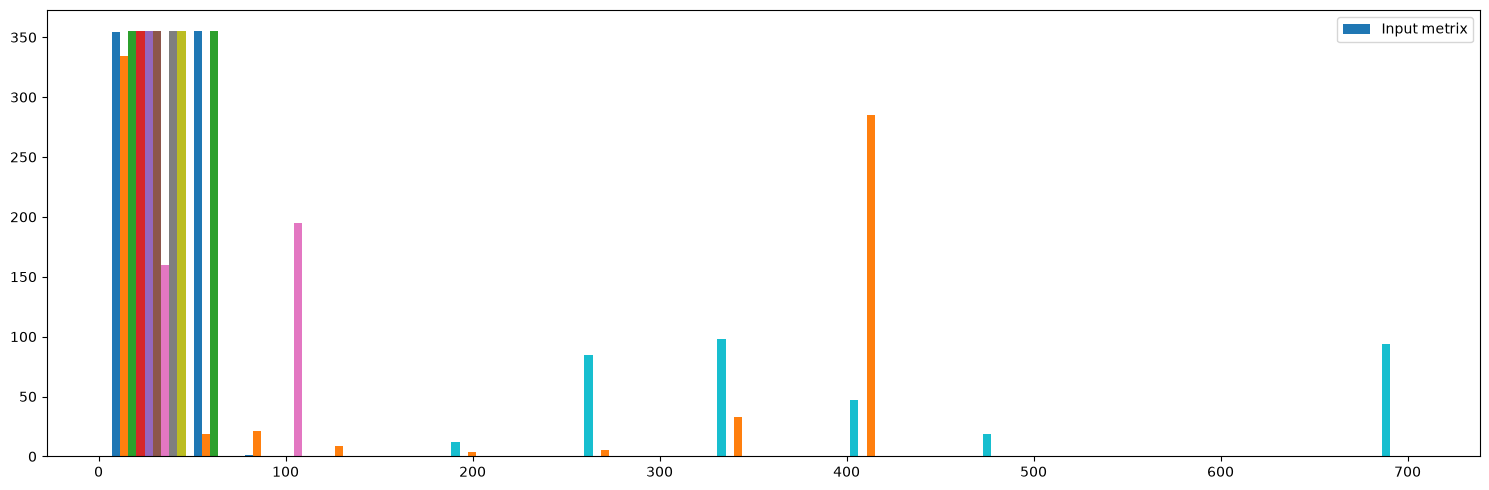

In [14]:
plt.figure(figsize=(15,5))

plt.hist(X, label='Input metrix') ## Histogram of the whole features input matrix 
plt.legend()
plt.tight_layout()
plt.show()


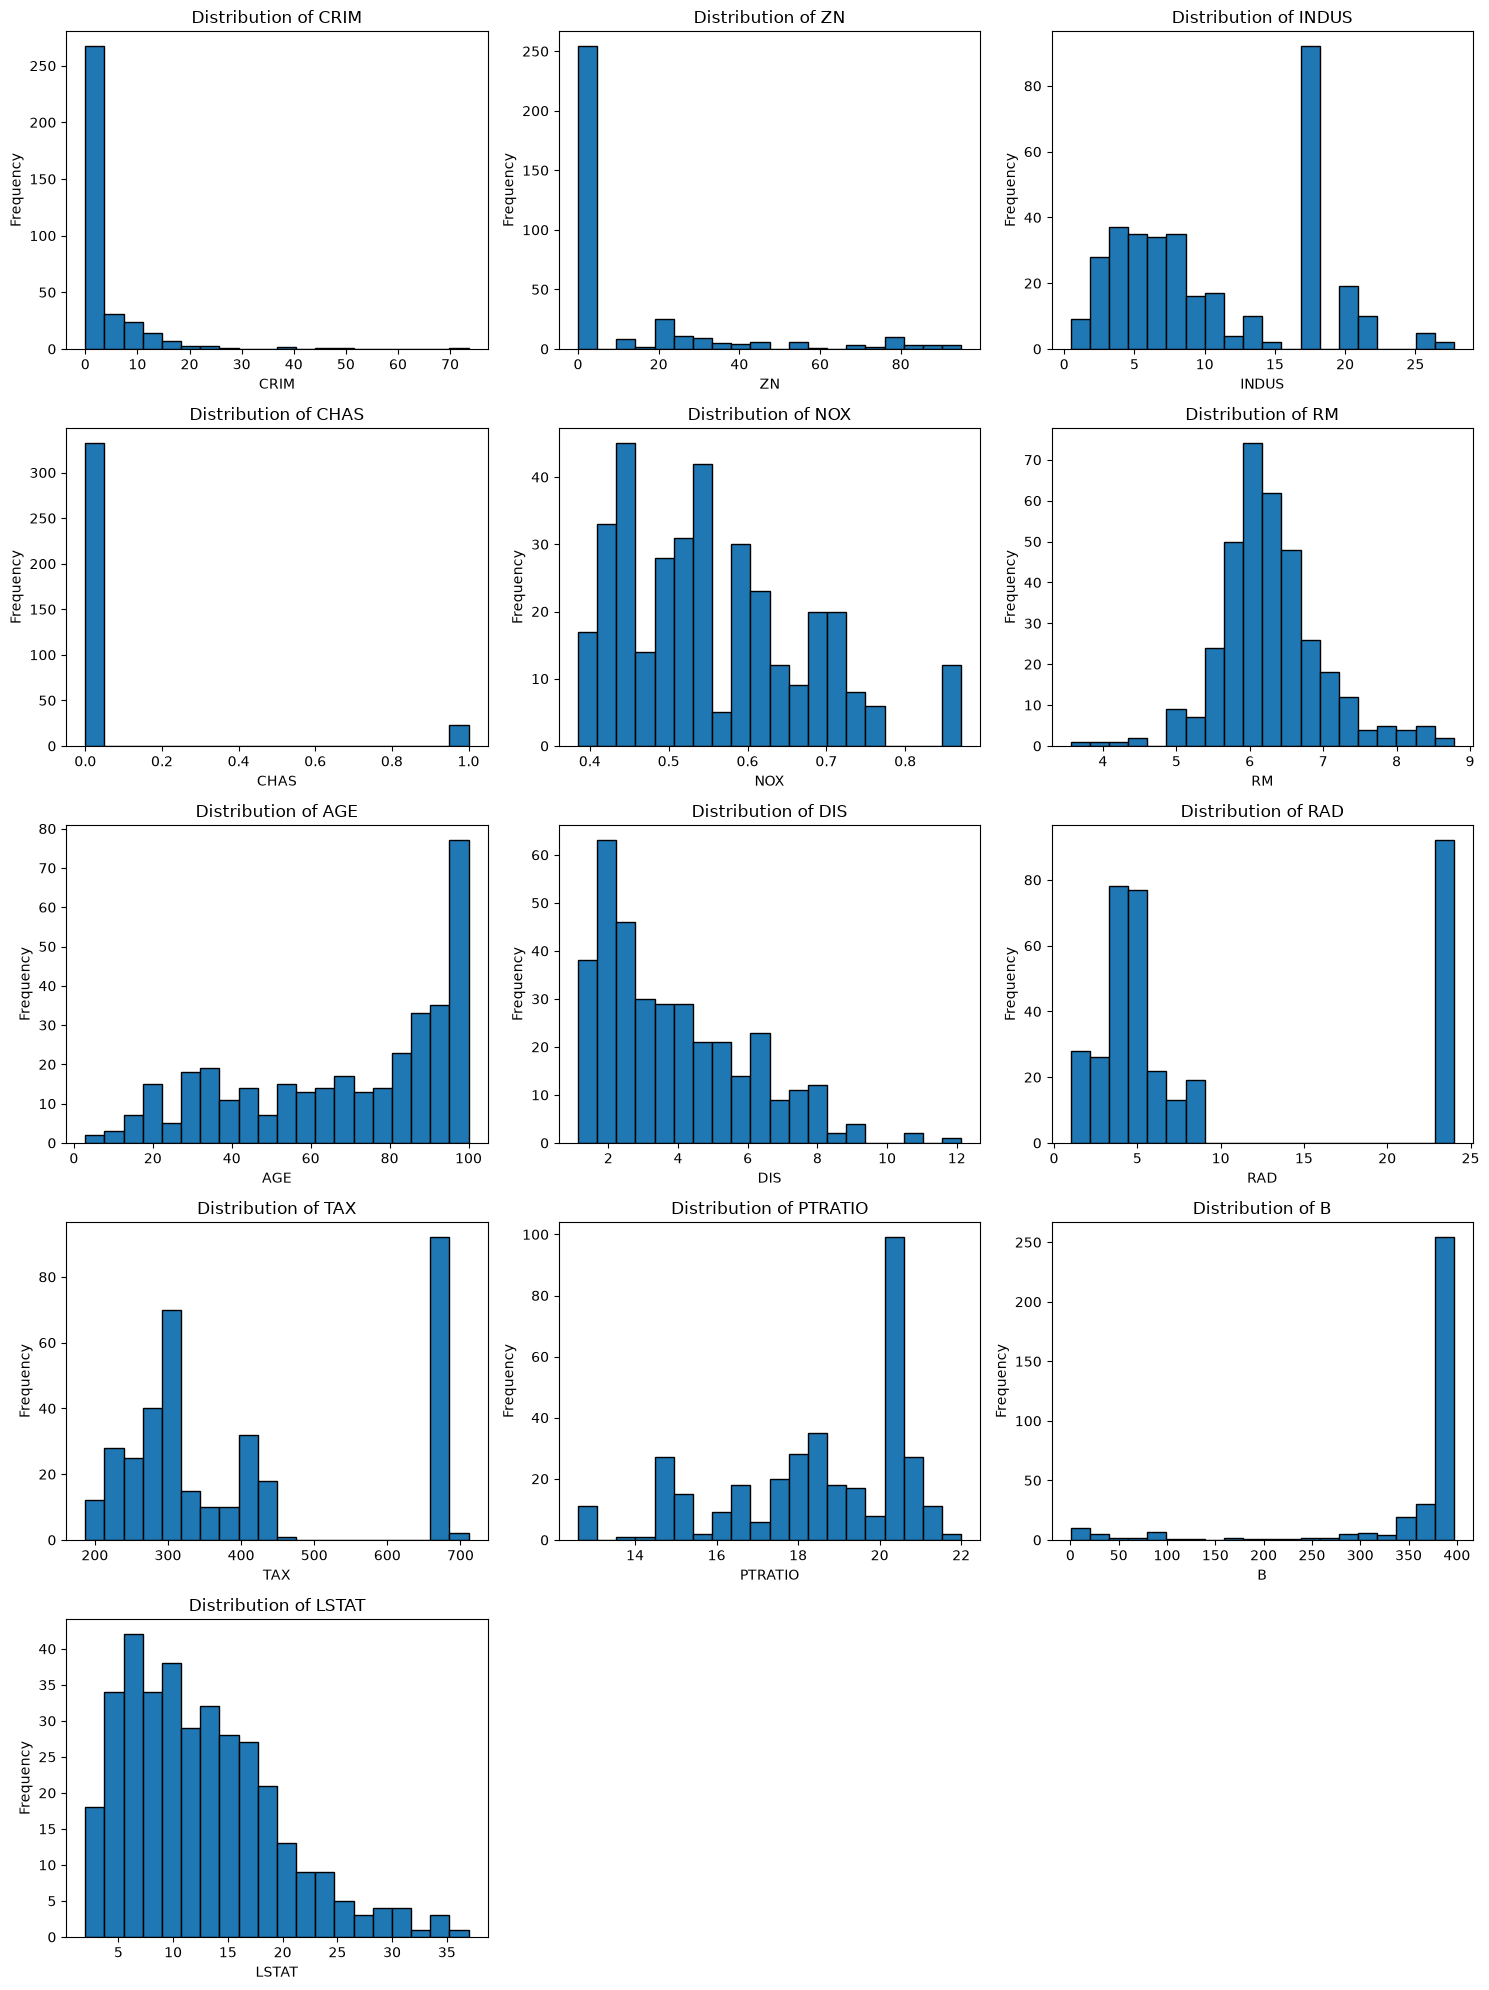

In [15]:
'''for column in X.columns:
    plt.hist(X[column], label=column)
    plt.legend()
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.show()
   '''
   
ncols = 3
nrows = (len(X.columns) + ncols - 1) // ncols

plt.figure(figsize=(15, 4 * nrows))

for i, column in enumerate(X.columns, start=1):
    plt.subplot(nrows, ncols, i)
    plt.hist(X[column], bins=20, edgecolor="black")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.title(f"Distribution of {column}")

plt.tight_layout()
plt.show()

Above is the distribution of individual features. (Univariate EDA) 

Now ploting every features agains MEDV(output values). (Bivariate EDA)

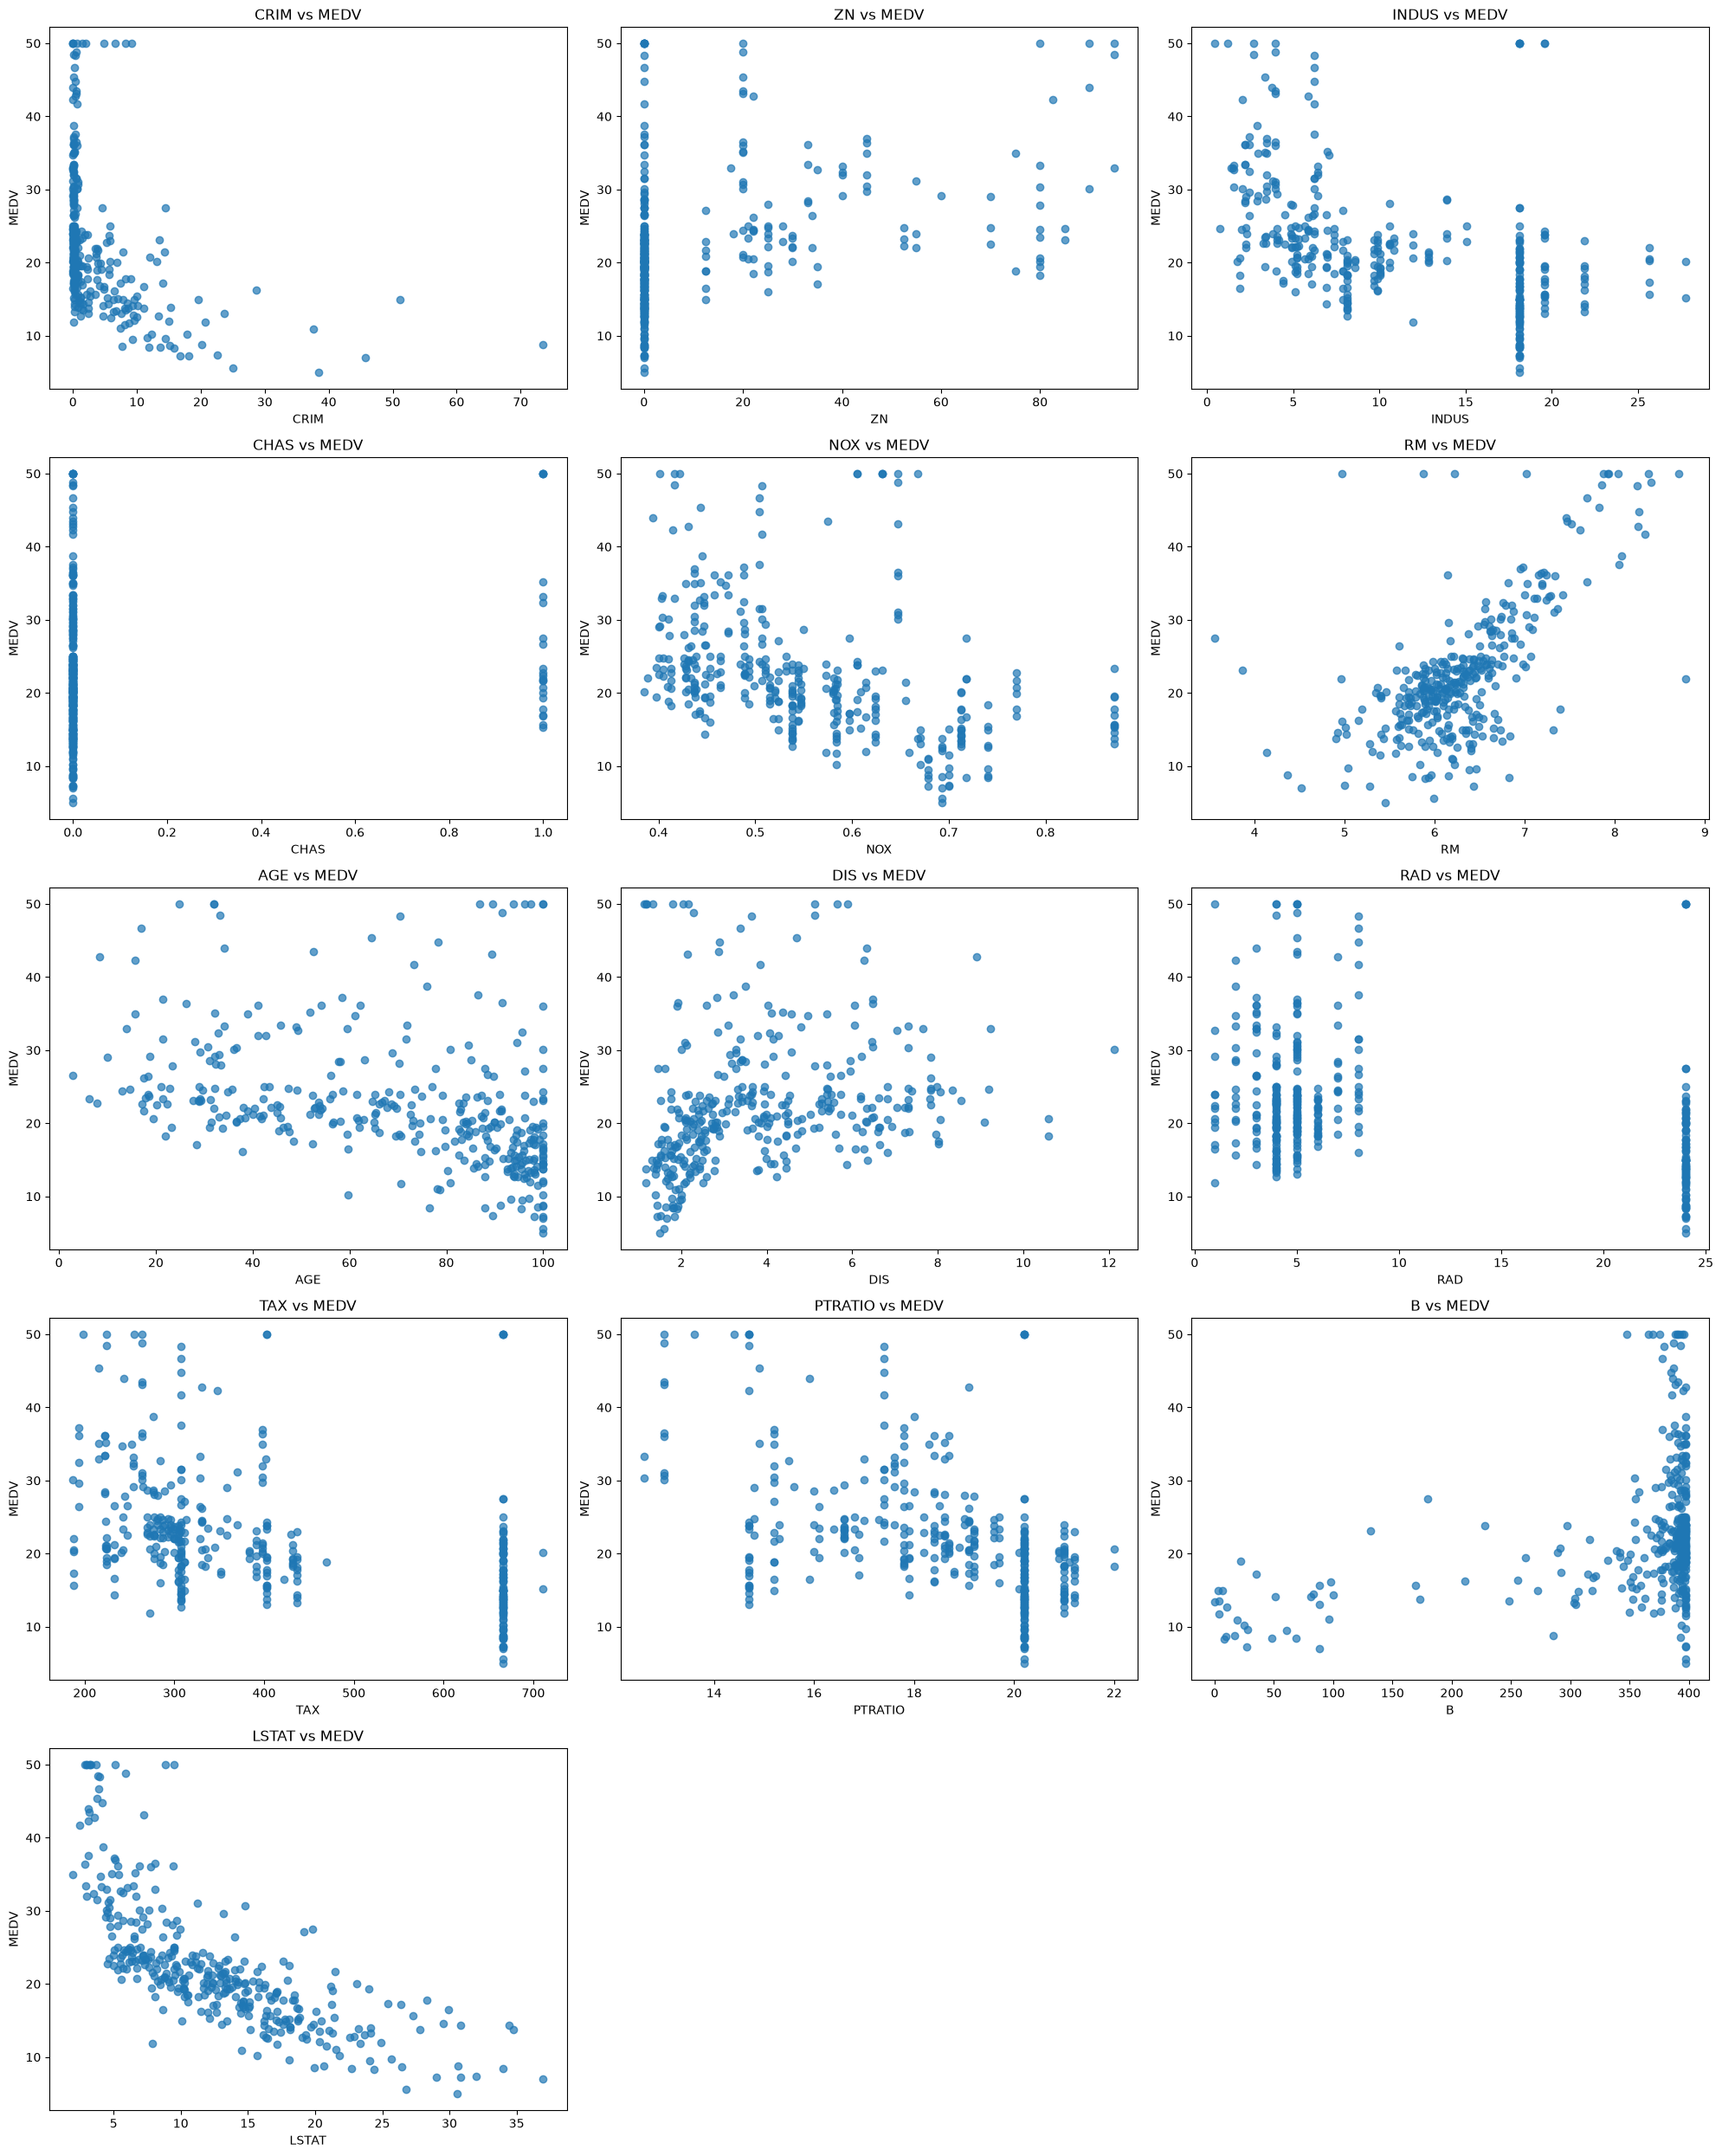

In [16]:
ncols = 3
nrows = (len(X.columns) + ncols - 1) // ncols

plt.figure(figsize=(20, 5* nrows))

for i, column in enumerate(X.columns, start=1):
    plt.subplot(nrows, ncols, i)
    plt.scatter(X[column], y, alpha=0.7)
    plt.xlabel(column)
    plt.ylabel(y.name)
    plt.title(f"{column} vs {y.name}")

plt.tight_layout()
plt.show()

In [17]:
correlation = train.corr(numeric_only=True)["MEDV"].sort_values()

print(correlation) # Correlation tells you how strongly two variables have a linear relationship and in which direction.
'''
Its value is between −1 and +1.
- Positive → when feature increases, MEDV tends to increase.
- Negative → when feature increases, MEDV tends to decrease.
- Closer to 0 → weaker linear relationship.
- Closer to ±1 → stronger linear relationship.
'''

LSTAT     -0.728913
PTRATIO   -0.506954
INDUS     -0.486016
TAX       -0.439541
NOX       -0.411615
AGE       -0.385713
CRIM      -0.384558
RAD       -0.363688
CHAS       0.144943
DIS        0.237746
B          0.357081
ZN         0.395225
RM         0.666058
MEDV       1.000000
Name: MEDV, dtype: float64


'\nIts value is between −1 and +1.\n- Positive → when feature increases, MEDV tends to increase.\n- Negative → when feature increases, MEDV tends to decrease.\n- Closer to 0 → weaker linear relationship.\n- Closer to ±1 → stronger linear relationship.\n'

## Now Focusing on building the model

In [18]:
from sklearn.model_selection import train_test_split

In [19]:
# This will splite the data set for training and testing
X_train,X_val,  y_train, y_val=train_test_split(X, y, test_size=0.2,   random_state=42)

## Evaluation metric for the model 

In [20]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error , r2_score, make_scorer ## these will be our evaluation metric 

In [21]:
def scores(y_true, y_predict):
    print("MSE:  ",mean_squared_error(y_true, y_predict))
    print("MAE:  ",mean_absolute_error(y_true, y_predict))
    print("RMSE: ",root_mean_squared_error(y_true, y_predict))
    print("R2:   ",r2_score(y_true, y_predict))

# Baseline Models

Linbraries to import

In [22]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Model_1

In [23]:
# Making baseline model 
from sklearn.linear_model import LinearRegression

In [24]:
model_1=Pipeline([
    ('scaler', StandardScaler()),
    ('model',LinearRegression())
])


model_1.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['CRIM','ZN','INDUS',...,'PTRATIO','B','LSTAT']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [25]:
y_predict_1=model_1.predict(X_train)

In [26]:
scores(y_train, y_predict_1)

MSE:   18.92522758445674
MAE:   3.0436535176673534
RMSE:  4.350313504157688
R2:    0.7493832610930169


In [27]:
y_validation_1=model_1.predict(X_val)

In [28]:
scores(y_val,y_validation_1)

MSE:   37.42336009311381
MAE:   3.794317725799108
RMSE:  6.117463534269232
R2:    0.6494606740225277


## Now using another models to see the performances 

# Model_2

# Decision Tree

In [29]:
from sklearn.tree import DecisionTreeRegressor

Decision tree does not need for scaling features because it uses threshould for spliting the nodes 

In [30]:
model_2=DecisionTreeRegressor(random_state=7)

model_2.fit(X_train,y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",7
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes m

In [31]:
y_predict_2=model_2.predict(X_train)

In [32]:
# Now evaluating the model and finding the scores 
scores(y_train,y_predict_2)

MSE:   0.0
MAE:   0.0
RMSE:  0.0
R2:    1.0


Very good model is this

In [33]:
# Finding the scores on the validation set 
y_validation_2=model_2.predict(X_val)
scores(y_val,y_validation_2)


MSE:   39.23014084507043
MAE:   3.625352112676057
RMSE:  6.26339690943105
R2:    0.6325368140216059


Don't be surprised if that happens.

A fully grown Decision Tree can become extremely complex and memorize the training data.

# Model_3

# XGBoost

It is not part of sklearn library, it is presend as a different package which follows same sklearn setimater API. 

In [34]:
# Downloading the library 
# %pip install xgboost

In [35]:
# %pip show xgboost

In [36]:
from xgboost import XGBRegressor

In [37]:
model_3=XGBRegressor(random_state=49)

In [38]:
model_3.fit(X_train, y_train)
y_predict_3=model_3.predict(X_train)
scores(y_train,y_predict_3)

MSE:   1.6847549242946022e-05
MAE:   0.0028458968014784076
RMSE:  0.004104576621643945
R2:    0.999999776896852


In [39]:
# Valindation on validation set
y_validation_3=model_3.predict(X_val)
scores(y_val, y_validation_3)

MSE:   22.489983030027005
MAE:   2.9153378177696556
RMSE:  4.742360491361555
R2:    0.7893395068487956


# Model_4

# Random_Forest

In [40]:
from sklearn.ensemble import RandomForestRegressor

In [41]:
import sklearn.ensemble

In [42]:
[name for name in dir(sklearn.ensemble) if not name.startswith("_")]

['AdaBoostClassifier',
 'AdaBoostRegressor',
 'BaggingClassifier',
 'BaggingRegressor',
 'BaseEnsemble',
 'ExtraTreesClassifier',
 'ExtraTreesRegressor',
 'GradientBoostingClassifier',
 'GradientBoostingRegressor',
 'HistGradientBoostingClassifier',
 'HistGradientBoostingRegressor',
 'IsolationForest',
 'RandomForestClassifier',
 'RandomForestRegressor',
 'RandomTreesEmbedding',
 'StackingClassifier',
 'StackingRegressor',
 'VotingClassifier',
 'VotingRegressor']

In [43]:
model_4=RandomForestRegressor(random_state=49)

In [44]:
model_4.fit(X_train,y_train)
y_predict_4=model_4.predict(X_train)
scores(y_train,y_predict_4)

MSE:   1.861237394366197
MAE:   0.8700140845070412
RMSE:  1.3642717450589517
R2:    0.9753526215721238


In [45]:
y_validation_4=model_4.predict(X_val)
scores(y_val, y_validation_4)

MSE:   18.139469577464773
MAE:   2.529267605633801
RMSE:  4.259045618147893
R2:    0.8300901516204742


## best model currently is Random Forest 

## Hyper parameter tuning for getting best Random forest model 

In [46]:
from sklearn.model_selection import GridSearchCV

In [47]:
model=GridSearchCV(
    estimator=RandomForestRegressor(random_state=49),
    param_grid={'n_estimators': [100,200],
                'max_depth':[ None, 10, 20] ,
                'min_samples_split': [2,3,4],  
                'min_samples_leaf' : [1,2,3,4],
                'max_features':['sqrt', 'log2']  
        },
    scoring={
        'rmse':'neg_root_mean_squared_error',
        'r2':make_scorer(r2_score)  # 'r2': 'r2'  Here Both will work, and this is prefered. 
    },
    refit='r2',
    cv=5,
    n_jobs=-1
)

In [48]:
model.fit(X_train,y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=49)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [None, 10, ...], 'max_features': ['sqrt', 'log2'], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 3, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'r2': make_scorer(r...hod='predict'), 'rmse': 'neg_root_mean_squared_error'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'r2'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versi

In [49]:
pd.DataFrame(model.cv_results_)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_max_depth,param_max_features,param_min_samples_leaf,param_min_samples_split,param_n_estimators,params,...,std_test_rmse,rank_test_rmse,split0_test_r2,split1_test_r2,split2_test_r2,split3_test_r2,split4_test_r2,mean_test_r2,std_test_r2,rank_test_r2
0,0.309210,0.044650,0.018122,0.003405,None,sqrt,1,2,100,"{'max_depth': None, 'max_features': 'sqrt', 'm...",...,0.727079,5,0.858075,0.861893,0.574140,0.860490,0.877294,0.806378,0.116315,5
1,0.514257,0.061350,0.061230,0.028779,None,sqrt,1,2,200,"{'max_depth': None, 'max_features': 'sqrt', 'm...",...,0.785088,9,0.855942,0.865683,0.551697,0.868209,0.870411,0.802388,0.125443,17
2,0.287993,0.024743,0.017921,0.003718,None,sqrt,1,3,100,"{'max_depth': None, 'max_features': 'sqrt', 'm...",...,0.748500,21,0.858904,0.867769,0.565633,0.867218,0.856970,0.803299,0.118911,9
3,0.375677,0.057773,0.030845,0.010018,None,sqrt,1,3,200,"{'max_depth': None, 'max_features': 'sqrt', 'm...",...,0.799456,29,0.859397,0.872995,0.548262,0.869560,0.856350,0.801313,0.126676,25
4,0.162220,0.012378,0.016610,0.007594,None,sqrt,1,4,100,"{'max_depth': None, 'max_features': 'sqrt', 'm...",...,0.796826,17,0.868573,0.868022,0.539510,0.861437,0.864080,0.800324,0.130434,33
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,0.305380,0.026764,0.026630,0.002485,20,log2,4,2,200,"{'max_depth': 20, 'max_features': 'log2', 'min...",...,0.777052,127,0.818862,0.841754,0.514894,0.849744,0.829164,0.770884,0.128430,127
140,0.132854,0.005904,0.012973,0.001196,20,log2,4,3,100,"{'max_depth': 20, 'max_features': 'log2', 'min...",...,0.777123,115,0.825043,0.843681,0.517954,0.853764,0.830515,0.774192,0.128512,115
141,0.284068,0.017155,0.024407,0.004188,20,log2,4,3,200,"{'max_depth': 20, 'max_features': 'log2', 'min...",...,0.777052,127,0.818862,0.841754,0.514894,0.849744,0.829164,0.770884,0.128430,127
142,0.145783,0.015615,0.014924,0.002273,20,log2,4,4,100,"{'max_depth': 20, 'max_features': 'log2', 'min...",...,0.777123,115,0.825043,0.843681,0.517954,0.853764,0.830515,0.774192,0.128512,115


In [50]:
y_predict=model.predict(X_train)
scores(y_train, y_predict)

MSE:   1.8901180828601003
MAE:   0.9704927363848368
RMSE:  1.374815654136983
R2:    0.97497016995111


In [51]:
y_validation=model.predict(X_val)
scores(y_val, y_validation)

MSE:   17.85054935405101
MAE:   2.5341482886328017
RMSE:  4.224991047807204
R2:    0.832796426528038


This is the score of our Best model currently we have

Inspecting wining configuration 

In [52]:
print(model.best_params_)

{'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}


In [53]:
## Average performance across five validation folds during GridSearchCV
print("Best CV R^2 : ",model.best_score_) 

Best CV R^2 :  0.8069978205937369


## Again training this best model on all the training set 

In [54]:
model.fit(X,y)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=49)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [None, 10, ...], 'max_features': ['sqrt', 'log2'], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 3, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'r2': make_scorer(r...hod='predict'), 'rmse': 'neg_root_mean_squared_error'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'r2'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versi

In [55]:
y_predict=model.predict(X)
scores(y, y_predict)

MSE:   1.9923461514690284
MAE:   0.9859244178953582
RMSE:  1.4115049243516753
R2:    0.9756581928108531


In [56]:
print(model.best_params_)

{'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}


In [57]:
## Average performance across five validation folds during GridSearchCV
print("Best CV R^2 : ",model.best_score_) 

Best CV R^2 :  0.8352168654967906


# Getting test results and submitting the output in kaggle 

In [69]:
test.head()

,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT
0,2,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14
1,6,0.02985,0.0,2.18,0,0.458,6.430,58.7,6.0622,3,222,18.7,394.12,5.21
2,33,1.38799,0.0,8.14,0,0.538,5.950,82.0,3.9900,4,307,21.0,232.60,27.71
3,34,1.15172,0.0,8.14,0,0.538,5.701,95.0,3.7872,4,307,21.0,358.77,18.35
4,36,0.06417,0.0,5.96,0,0.499,5.933,68.2,3.3603,5,279,19.2,396.90,9.68


In [70]:
test.drop(['Unnamed: 0'], axis=1)

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT
0,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14
1,0.02985,0.0,2.18,0,0.458,6.430,58.7,6.0622,3,222,18.7,394.12,5.21
2,1.38799,0.0,8.14,0,0.538,5.950,82.0,3.9900,4,307,21.0,232.60,27.71
3,1.15172,0.0,8.14,0,0.538,5.701,95.0,3.7872,4,307,21.0,358.77,18.35
4,0.06417,0.0,5.96,0,0.499,5.933,68.2,3.3603,5,279,19.2,396.90,9.68
...,...,...,...,...,...,...,...,...,...,...,...,...,...
146,0.18337,0.0,27.74,0,0.609,5.414,98.3,1.7554,4,711,20.1,344.05,23.97
147,0.20746,0.0,27.74,0,0.609,5.093,98.0,1.8226,4,711,20.1,318.43,29.68
148,0.10574,0.0,27.74,0,0.609,5.983,98.8,1.8681,4,711,20.1,390.11,18.07
149,0.27957,0.0,9.69,0,0.585,5.926,42.6,2.3817,6,391,19.2,396.90,13.59


In [71]:
test.head()

,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT
0,2,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14
1,6,0.02985,0.0,2.18,0,0.458,6.430,58.7,6.0622,3,222,18.7,394.12,5.21
2,33,1.38799,0.0,8.14,0,0.538,5.950,82.0,3.9900,4,307,21.0,232.60,27.71
3,34,1.15172,0.0,8.14,0,0.538,5.701,95.0,3.7872,4,307,21.0,358.77,18.35
4,36,0.06417,0.0,5.96,0,0.499,5.933,68.2,3.3603,5,279,19.2,396.90,9.68


In [72]:
y_test_predicted=model.predict(test.drop(['Unnamed: 0'], axis=1))

In [74]:
test['Unnamed: 0']

0        2
1        6
2       33
3       34
4       36
      ... 
146    490
147    491
148    492
149    495
150    505
Name: Unnamed: 0, Length: 151, dtype: int64

In [73]:
pd.Series( y_test_predicted )

0      23.455901
1      26.857063
2      15.065271
3      14.510147
4      21.803412
         ...    
146    16.212903
147    16.043681
148    17.392611
149    20.395673
150    23.646955
Length: 151, dtype: float64

Making this prediction into csv file and then saving it and then submitting it.

Creating the submission file

In [75]:
submission=pd.DataFrame({'ID':test['Unnamed: 0'],'MEDV':y_test_predicted})

In [76]:
submission.head()

,ID,MEDV
0,2,23.455901
1,6,26.857063
2,33,15.065271
3,34,14.510147
4,36,21.803412


Saving this as a csv file

In [77]:
submission.to_csv("test_results.csv", index=False)